# 随机森林
由许多决策树组成的“森林”

## 准备数据

In [1]:
# 以下生成数据、建树和画图的代码与决策树一文相同
import math
import torch
from sympy import shape

torch.set_num_threads(1)

# 两个月牙各 500 个点：上面的月牙是蓝点，标签为 0；下面的月牙是红点，标签为 1
generator = torch.Generator().manual_seed(2)
angle = math.pi * torch.rand(1000, generator=generator)
upper = torch.stack([torch.cos(angle[:500]), torch.sin(angle[:500])], dim=1)
lower = torch.stack([1 - torch.cos(angle[500:]), 0.5 - torch.sin(angle[500:])], dim=1)
# 每个坐标再加上标准差为 0.3 的随机噪声，两个月牙会有一部分交叠
x = torch.cat([upper, lower]) + 0.3 * torch.randn(1000, 2, generator=generator)
y = torch.cat([torch.zeros(500), torch.ones(500)])

# 打乱后按 6:2:2 分成训练集、验证集和测试集
order = torch.randperm(1000, generator=torch.Generator().manual_seed(42))
train_ids, val_ids, test_ids = order[:600], order[600:800], order[800:]
x_train, y_train = x[train_ids], y[train_ids]
x_val, y_val = x[val_ids], y[val_ids]
x_test, y_test = x[test_ids], y[test_ids]

import matplotlib.pyplot as plt


# 绘图辅助：把平面上每个位置交给模型，画出分类区域、决策边界和训练点
def plot_boundary(ax, predict_fn, title, xs=None, ys=None):
    xs = x_train if xs is None else xs
    ys = y_train if ys is None else ys
    grid_x, grid_y = torch.meshgrid(torch.linspace(-2, 3, 300), torch.linspace(-1.5, 2, 210), indexing="xy")
    p = predict_fn(torch.stack([grid_x.flatten(), grid_y.flatten()], dim=1)).reshape(grid_x.shape)
    # 判为蓝点的区域涂成浅蓝色，判为红点的区域涂成浅红色，交界处的黑线就是决策边界
    ax.contourf(grid_x, grid_y, (p > 0.5).float(), levels=[-0.5, 0.5, 1.5], colors=["#d6e6f5", "#f8dcd0"])
    ax.contour(grid_x, grid_y, p, levels=[0.5], colors="black", linewidths=1)
    ax.scatter(xs[ys == 0, 0], xs[ys == 0, 1], s=6, color="#2b6cb0")
    ax.scatter(xs[ys == 1, 0], xs[ys == 1, 1], s=6, color="#c0392b")
    ax.set(xlim=(-2, 3), ylim=(-1.5, 2), aspect="equal", title=title)

## 训练阶段——构建森林
1. Bootstrap 自助采样
> - 有放回抽样：对于森林中的每一棵决策树，算法会从原始数据集中有放回地随机抽取 $N$ 个样本。
> - 结果：这意味着有些样本会被多次抽到，而大约有 $36.8\%$ 的样本在这一轮中完全没有被抽到
> - （这部分未被抽到的数据被称为 OOB（Out-of-Bag，袋外数据），可以直接用来评估模型的泛化性能，而无需单独划分测试集）。



In [16]:
generator = torch.Generator().manual_seed(0)


# 从 n 个训练点里有放回地抽 n 次，返回抽到的编号
def bootstrap(n):
    # 编号范围0~n-1
    return torch.randint(n, (n,), generator=generator)

samples = [bootstrap(600) for _ in range(4)]
print(f"一共有{len(samples)}份Bootstrap样本，可以训练{len(samples)}棵树，每份里面有{samples[0].shape[0]}个数据")

一共有4份Bootstrap样本，可以训练4棵树，每份里面有600个数据


2. 特征随机
> - 算法不会评估全部的 $M$ 个特征，而是从所有特征中随机选择一个包含 $m$ 个特征的子集（通常 $m = \sqrt{M}$ 或 $\log_2 M$）

3. 生成决策树


In [18]:
# p 是节点里红点所占的比例，返回这个节点的基尼不纯度
def gini(p):
    return 1 - p ** 2 - (1 - p) ** 2


# 用某个特征的每个候选阈值切一刀，算出切分后的加权基尼不纯度
def split_scores(x, y, feature):
    # 这个特征的取值去重后从小到大排好，相邻两个值的中点就是候选阈值
    values = torch.unique(x[:, feature])
    thresholds = (values[:-1] + values[1:]) / 2
    # go_left 的第 i 行表示用第 i 个阈值切分时，每个点是否分到左边，形状是 (阈值个数, 点数)
    go_left = x[:, feature] <= thresholds[:, None]
    n_left = go_left.sum(dim=1)
    n_right = len(y) - n_left
    p_left = (go_left * y).sum(dim=1) / n_left
    p_right = (~go_left * y).sum(dim=1) / n_right
    # 两边的基尼不纯度按点数加权
    impurity = (n_left * gini(p_left) + n_right * gini(p_right)) / len(y)
    return thresholds, impurity


# 在所有特征的所有候选阈值里，找出加权基尼不纯度最小的切分
def best_split(x, y):
    best = None
    for feature in range(x.shape[1]):
        thresholds, impurity = split_scores(x, y, feature)
        i = impurity.argmin()
        if best is None or impurity[i] < best[0]:
            best = (impurity[i].item(), feature, thresholds[i].item())
    return best


def build_tree(x, y, depth=0, max_depth=None):
    p = y.mean().item()
    # 节点里只剩一种颜色，或者深度到了上限，就不再切分，作为叶子节点
    if p in (0.0, 1.0) or depth == max_depth:
        return {"p": p, "n": len(y)}
    _, feature, threshold = best_split(x, y)
    left = x[:, feature] <= threshold
    # 分到左右两边的点，各自重复同样的过程，长出左子树和右子树
    return {
        "feature": feature,
        "threshold": threshold,
        "left": build_tree(x[left], y[left], depth + 1, max_depth),
        "right": build_tree(x[~left], y[~left], depth + 1, max_depth),
    }

In [30]:
trees = [build_tree(x_train[s], y_train[s]) for s in samples]

In [32]:
# 从根节点出发，按节点上的问题把点分到左边或右边，返回每个点最终所在叶子的红点比例
def predict(node, x):
    if "p" in node:
        return torch.full((len(x),), node["p"])
    left = x[:, node["feature"]] <= node["threshold"]
    p = torch.empty(len(x))
    p[left] = predict(node["left"], x[left])
    p[~left] = predict(node["right"], x[~left])
    return p


# 红点比例超过 0.5 就判为红点，统计判对的比例
def accuracy(tree, xs, ys):
    return ((predict(tree, xs) > 0.5).float() == ys).float().mean().item()

第 1 棵树：测试集准确率 89.0%
第 2 棵树：测试集准确率 84.0%
第 3 棵树：测试集准确率 86.0%
第 4 棵树：测试集准确率 86.5%


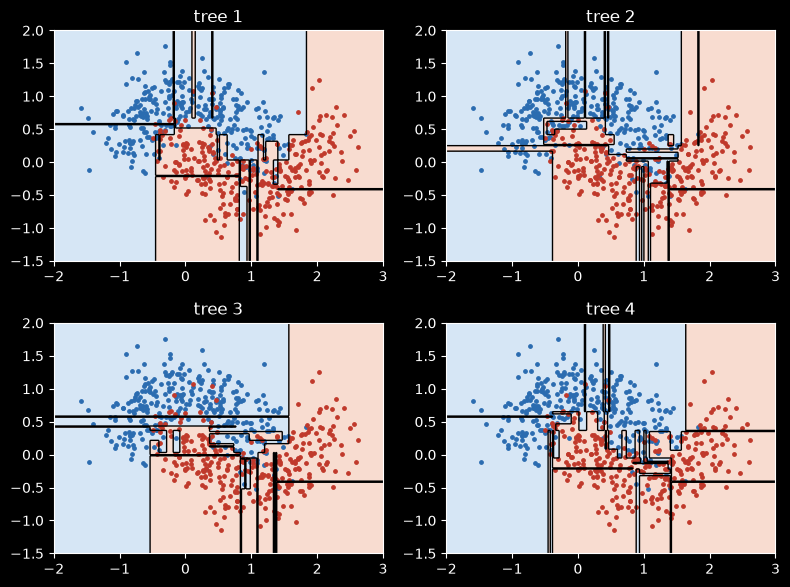

In [33]:
for i, tree in enumerate(trees):
    print(f"第 {i + 1} 棵树：测试集准确率 {accuracy(tree, x_test, y_test):.1%}")

fig, axes = plt.subplots(2, 2, figsize=(8, 6))
for i, (tree, ax) in enumerate(zip(trees, axes.flat)):
    plot_boundary(ax, lambda points: predict(tree, points), f"tree {i + 1}")
fig.tight_layout()
plt.show()

4. 多棵决策树组成“随机森林”

- Bagging：让很多棵树投票

In [34]:
# 每棵树用一份新的 Bootstrap 样本训练，不限制深度
def train_forest(x, y, n_trees, generator):
    trees = []
    for _ in range(n_trees):
        ids = torch.randint(len(y), (len(y),), generator=generator)
        trees.append(build_tree(x[ids], y[ids]))
    return trees


# 每棵树给出一个红点比例，取平均作为森林的预测
def predict_forest(trees, x):
    return torch.stack([predict(tree, x) for tree in trees]).mean(dim=0)


forest = train_forest(x_train, y_train, 100, torch.Generator().manual_seed(0))
for k in [1, 5, 10, 20, 50, 100]:
    p = predict_forest(forest[:k], x_test)
    print(f"前 {k:3d} 棵树：测试集准确率 {((p > 0.5).float() == y_test).float().mean():.1%}")

前   1 棵树：测试集准确率 89.0%
前   5 棵树：测试集准确率 87.0%
前  10 棵树：测试集准确率 90.5%
前  20 棵树：测试集准确率 90.0%
前  50 棵树：测试集准确率 91.0%
前 100 棵树：测试集准确率 91.0%


5. 预测
> - 分类任务——多数表决
> - 回归任务——取平均值

# 预测房价

In [37]:
import numpy as np

# 每行是一个街区，前 8 列是特征，最后一列是房价中位数，单位是千美元
data = np.loadtxt("datasets/californiaHouse/california.csv", delimiter=",", skiprows=1)
names = ["收入", "房龄", "房间数", "卧室数", "人口", "每户人数", "纬度", "经度"]
x = data[:, :8]
# 房价中位数超过 18 万美元的街区，标签为 1
y = (data[:, 8] > 180).astype(int)

print(f"共 {len(y)} 个街区，标签为 1 的占 {y.mean():.1%}")
for row in data[:3]:
    print("，".join(f"{name} {value:g}" for name, value in zip(names, row)) + f"，房价 {row[8]:g}")

共 20640 个街区，标签为 1 的占 49.7%
收入 8.33，房龄 41，房间数 6.98，卧室数 1.02，人口 322，每户人数 2.56，纬度 37.88，经度 -122.23，房价 453
收入 8.3，房龄 21，房间数 6.24，卧室数 0.97，人口 2401，每户人数 2.11，纬度 37.86，经度 -122.22，房价 358
收入 7.26，房龄 52，房间数 8.29，卧室数 1.07，人口 496，每户人数 2.8，纬度 37.85，经度 -122.24，房价 352


In [40]:
# 打乱后按 6:2:2 分成训练集、验证集和测试集
n = len(y)
order = np.random.default_rng(42).permutation(n)
train_ids, val_ids, test_ids = order[: int(n * 0.6)], order[int(n * 0.6) : int(n * 0.8)], order[int(n * 0.8) :]
x_train, y_train = x[train_ids], y[train_ids]
x_val, y_val = x[val_ids], y[val_ids]
x_test, y_test = x[test_ids], y[test_ids]

In [41]:
from sklearn.tree import DecisionTreeClassifier

# 依次尝试几个深度上限，None 表示不限深度
depths = [4, 6, 8, 10, 12, None]
val_accs = []
for depth in depths:
    # 只用训练集建树；random_state 固定随机种子，每次运行都得到同样的树
    tree = DecisionTreeClassifier(max_depth=depth, random_state=0).fit(x_train, y_train)
    # score 返回准确率，挑选深度时只看训练集和验证集
    val_accs.append(tree.score(x_val, y_val))
    label = "不限深度" if depth is None else f"深度 {depth}"
    print(f"{label}：训练集 {tree.score(x_train, y_train):.1%}，验证集 {val_accs[-1]:.1%}，{tree.get_n_leaves()} 个叶子")

# 挑出验证集准确率最高的深度，用它建出最终的单棵树
best_depth = depths[val_accs.index(max(val_accs))]
tree = DecisionTreeClassifier(max_depth=best_depth, random_state=0).fit(x_train, y_train)
# 测试集只用来评估最终选出的这棵树
print(f"深度 {best_depth} 的树，测试集准确率：{tree.score(x_test, y_test):.1%}")

深度 4：训练集 78.5%，验证集 77.9%，16 个叶子
深度 6：训练集 82.7%，验证集 81.4%，61 个叶子
深度 8：训练集 88.3%，验证集 84.2%，192 个叶子
深度 10：训练集 91.9%，验证集 85.6%，451 个叶子
深度 12：训练集 95.4%，验证集 85.4%，732 个叶子
不限深度：训练集 100.0%，验证集 85.3%，1275 个叶子
深度 10 的树，测试集准确率：84.7%


In [42]:
from sklearn.ensemble import RandomForestClassifier

# n_estimators=100：训练 100 棵树，每棵树用一份 Bootstrap 样本，默认不限深度
# max_features="sqrt"：每个节点随机挑 √8 ≈ 2.8 个特征，向下取整为 2 个，只在这 2 个特征里找最好的问题
forest = RandomForestClassifier(n_estimators=100, max_features="sqrt", random_state=0).fit(x_train, y_train)
# 森林用的是默认设置，没有在验证集上挑参数，训练完直接在测试集上评估
print(f"随机森林，测试集准确率：{forest.score(x_test, y_test):.1%}")

随机森林，测试集准确率：89.2%


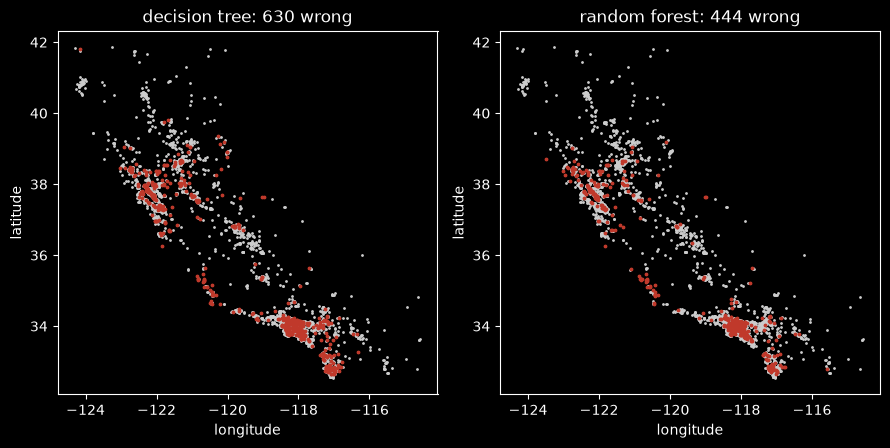

In [43]:
import matplotlib.pyplot as plt

# 左图是单棵树，右图是随机森林
fig, axes = plt.subplots(1, 2, figsize=(9, 4.6))
for model, title, ax in [(tree, "decision tree", axes[0]), (forest, "random forest", axes[1])]:
    # 预测结果和真实标签不一样的测试街区，就是判错的街区
    wrong = model.predict(x_test) != y_test
    # 第 7 列是经度，第 6 列是纬度；灰点是全部测试街区，红点是判错的街区
    ax.scatter(x_test[:, 7], x_test[:, 6], s=1, color="#cccccc")
    ax.scatter(x_test[wrong, 7], x_test[wrong, 6], s=3, color="#c0392b")
    ax.set(xlabel="longitude", ylabel="latitude", aspect="equal", title=f"{title}: {wrong.sum()} wrong")
fig.tight_layout()
plt.show()